In [1]:
import numpy as np
from cosmoTransitions.tunneling1D import SingleFieldInstanton
import matplotlib.pyplot as plt
import math
import pandas as pd
from scipy import optimize as optimize
import scipy.integrate as integrate
from scipy import interpolate, special


####Some definitions##
v2 = 246.**2 
mh=125
v=246
alpha=1/137 #fine structure constant
sinthw=np.sqrt(0.223) #sine of Weinberg angle
g1=np.sqrt(4*np.pi*alpha/(1-sinthw**2)) ## U(1)_Y gauge coupling constant
g=np.sqrt(4*np.pi*alpha)/sinthw #SU(2)_L gauge coupling constant
Mplanck=2.4*10**18 #reduced planck mass
mZ=np.sqrt(v**2/4*(g**2+g1**2))###Z boson mass

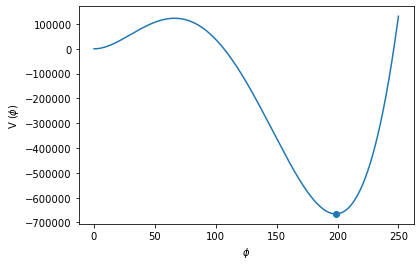

Difference between global minimum and the scape point is  3.8576985396248915


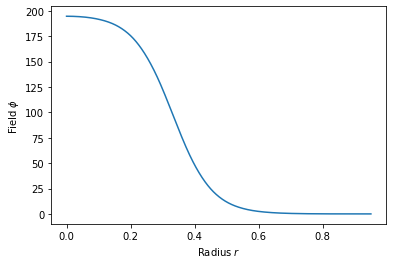

In [2]:
#Definition of the potential
#Formulas drawn from the paper "Bubble growth and droplet decay in cosmological phase transitions"
Tc = 100.
L = 0.1*Tc**4
sigma = 0.1*Tc**3
lc = 6/Tc
T0 = Tc/(1+6*sigma/(L*lc))**0.5
alpha = 1/(2/3*sigma*lc**5*Tc**2)**0.5
gamma = (L+6*sigma/lc)/(6*sigma*lc*Tc**2)
lam = 1/(3*sigma*lc**3)
Tn = 93.
def V(phi): return 0.5*gamma*(Tn**2-T0**2)*phi**2- 1/3*alpha*Tn*phi**3 + 0.25*lam*phi**4
def dV(phi): return gamma*(Tn**2-T0**2)*phi-alpha*Tn*phi**2+lam*phi**3

#Thermodynamic quantities #
gst = 106.75
a = gst*(np.pi**2)/90
def VT(field,temp): return 0.5*gamma*(temp**2-T0**2)*field**2-1/3*alpha*temp*field**3+0.25*lam*field**4
def dVT(field,temp): return gamma*(temp**2-T0**2)*field-alpha*temp*field**2+lam*field**3



#critical bubble#
xi = np.array(range(2500000))
Vmin = np.amin(V(xi))
phi_stable = xi[np.where(V(xi) == Vmin)[0]][0] ##find location of the global minimum
profile = SingleFieldInstanton(phi_stable, 0.0, V, dV).findProfile(npoints=1000)


plt.plot(xi, V(xi))
plt.xlabel(r"$\phi$")
plt.ylabel(r"V ($\phi$)")
plt.scatter(phi_stable,Vmin)
plt.show()
print("Difference between global minimum and the scape point is ",phi_stable-profile.Phi[0])

plt.plot(profile.R, profile.Phi)
plt.xlabel(r"Radius $r$")
plt.ylabel(r"Field $\phi$")
plt.show()

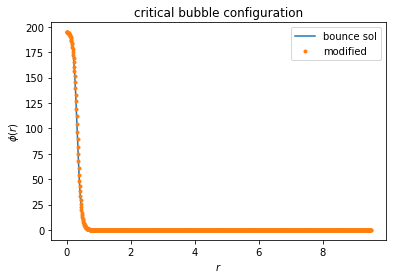

In [79]:
#initialization of the evolution#
profile = SingleFieldInstanton(phi_stable, 0.0, V, dV).findProfile(npoints=1000)
fphi = interpolate.interp1d(profile.R, profile.Phi, fill_value=(0), bounds_error=False)
r_steps=1000
R_size=10*profile.R[-1]
r_range  = np.linspace(profile.R[0],R_size,r_steps)

plt.plot(profile.R, profile.Phi,label="bounce sol")
plt.plot(r_range, fphi(r_range),".",label="modified")
plt.xlabel(r"$r$")
plt.ylabel(r"$\phi(r)$")
plt.title("critical bubble configuration")
plt.legend()
plt.show()



In [185]:
r_steps=1000
R_size=10*profile.R[-1]
r_range  = np.linspace(profile.R[0],R_size,r_steps)

t_steps=1000
t_size=1
t_range=np.linspace(0,t_size,t_steps)

phi_init = fphi(r_range/1.1) 
phi_dot_init=np.zeros([r_steps])


###Initialize order parameter vector and its time derivative
phi=phi_init
phi_dot=phi_dot_init
##Create lattices for order parameter and its time derivative
phi_lattice=np.zeros([t_steps,r_steps])
phi_lattice[0]=phi
phi_dot_lattice=np.zeros([t_steps,r_steps])
phi_dot_lattice[0]=phi_dot

### Loop over time (obtain the time evolution)
for tj in range(0,t_steps-1):
    dphi=[]
    ### Calculate discretized gradient in the bulk
    for ri in range(2,r_steps-1):
        delta_phi=1/r_range[ri]**2/(r_range[ri+1]-r_range[ri-1])*(phi[ri+1]-phi[ri])/(r_range[ri+1]-r_range[ri])*(r_range[ri+1]**2 + r_range[ri]**2)
        delta_phi-=1/r_range[ri]**2/(r_range[ri+1]-r_range[ri-1])*(phi[ri]-phi[ri-1])/(r_range[ri]-r_range[ri-1])*(r_range[ri]**2 + r_range[ri-1]**2)
        dphi.append(delta_phi)
    dphi=np.append([0,0],dphi)
    dphi=np.append(dphi,[0])
    dphi=np.array(dphi)
    
    ## Temporal discretization in velocity form 
    phi_dot= phi_dot - (t_range[tj+1]-t_range[tj])/2*(dV(phi) + dphi)
    phi_dot[0]=0
    phi_dot[-1]=0
    phi=phi + (t_range[tj+1]-t_range[tj])*phi_dot
    phi[0]=phi_init[0]
    phi[-1]=phi_init[-1]
    phi_lattice[tj+1]=phi
    
    dphi=[]
    ### Calculate discretized gradient in the bulk
    for ri in range(2,r_steps-1):
        delta_phi=1/r_range[ri]**2/(r_range[ri+1]-r_range[ri-1])*(phi[ri+1]-phi[ri])/(r_range[ri+1]-r_range[ri])*(r_range[ri+1]**2 + r_range[ri]**2)
        delta_phi-=1/r_range[ri]**2/(r_range[ri+1]-r_range[ri-1])*(phi[ri]-phi[ri-1])/(r_range[ri]-r_range[ri-1])*(r_range[ri]**2 + r_range[ri-1]**2)
        dphi.append(delta_phi)
    dphi=np.append([0,0],dphi)
    dphi=np.append(dphi,[0])
    dphi=np.array(dphi)
    
    phi_dot= phi_dot - (t_range[tj+1]-t_range[tj])/2*(dV(phi) + dphi)
    phi_dot[0]=0
    phi_dot[-1]=0
    phi_dot_lattice[tj+1]=phi_dot

    


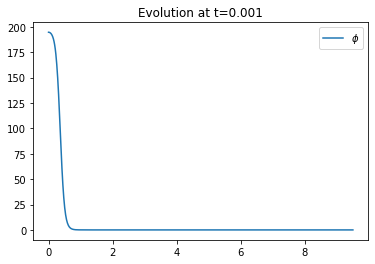

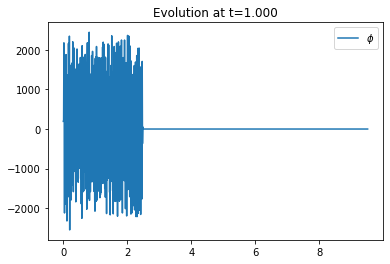

In [186]:
i=1
plt.plot(r_range,phi_lattice[i],label="$\\phi$")
#plt.plot(r_range,phi_dot_lattice[i],label="$\dot{\\phi}$")
plt.title("Evolution at t=%.3f"%t_range[i])
plt.legend()
plt.show()

i=-1
plt.plot(r_range,phi_lattice[i],label="$\\phi$")
#plt.plot(r_range,phi_dot_lattice[i],label="$\dot{\\phi}$")
plt.title("Evolution at t=%.3f"%t_range[i])
plt.legend()
plt.show() 

In [128]:
r_steps=1000
R_size=10*profile.R[-1]
r_range  = np.linspace(profile.R[0],R_size,r_steps)

t_steps=1000
t_size=1
t_range=np.linspace(0,t_size,t_steps)

phi_init = fphi(r_range/2.21) 
phi_dot_init=np.zeros([r_steps])


###Initialize order parameter vector and its time derivative
phi=phi_init
phi_dot=phi_dot_init
##Create lattices for order parameter and its time derivative
phi_lattice=np.zeros([t_steps,r_steps])
phi_lattice[0]=phi
phi_dot_lattice=np.zeros([t_steps,r_steps])
phi_dot_lattice[0]=phi_dot

### Loop over time (obtain the time evolution)
for tj in range(0,t_steps-1):
    dphi=[]
    ### Calculate discretized gradient in the bulk
    ## Temporal discretization in position form 
    phi=phi + (t_range[tj+1]-t_range[tj])/2*phi_dot
    for ri in range(1,r_steps-1):
        delta_phi=1/r_range[ri]**2/(r_range[ri+1]-r_range[ri-1])*(phi[ri+1]-phi[ri])/(r_range[ri+1]-r_range[ri])*(r_range[ri+1]**2 + r_range[ri]**2)
        delta_phi-=1/r_range[ri]**2/(r_range[ri+1]-r_range[ri-1])*(phi[ri]-phi[ri-1])/(r_range[ri]-r_range[ri-1])*(r_range[ri]**2 + r_range[ri-1]**2)
        dphi.append(delta_phi)
    dphi=np.append([0],dphi)
    dphi=np.append(dphi,[0])
    dphi=np.array(dphi)
    ## Temporal discretization in position form 
    phi_dot= phi - (t_range[tj+1]-t_range[tj])*(dV(phi) + dphi)
    phi=phi + (t_range[tj+1]-t_range[tj])/2*phi_dot
    
    phi[0]=phi_init[0]
    phi[-1]=phi_init[-1]
    phi_dot[0]=phi_dot_init[0]
    phi_dot[-1]=phi_dot_init[-1]
    
    phi_lattice[tj+1]=phi
    phi_dot_lattice[tj+1]=phi_dot
    
    


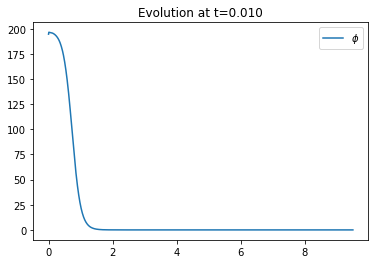

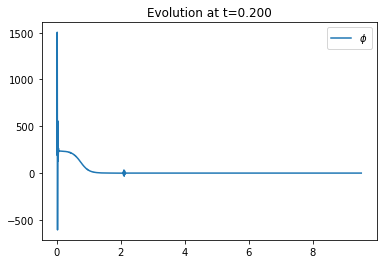

In [130]:
i=10
plt.plot(r_range,phi_lattice[i],label="$\\phi$")
#plt.plot(r_range,phi_dot_lattice[i],label="$\dot{\\phi}$")
plt.title("Evolution at t=%.3f"%t_range[i])
plt.legend()
plt.show()

i=200
plt.plot(r_range,phi_lattice[i],label="$\\phi$")
#plt.plot(r_range,phi_dot_lattice[i],label="$\dot{\\phi}$")
plt.title("Evolution at t=%.3f"%t_range[i])
plt.legend()
plt.show() 

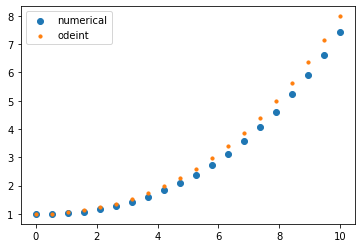

In [122]:
#### let us try Euler method
t_range=np.linspace(0,10,20)
y_sol=np.zeros(len(t_range))
y_sol[0]=1

def f(y,t):
    return y**(1/4)*.10*t

for t in range(1,len(t_range)):
    y_sol[t]=y_sol[t-1] + f(y_sol[t-1],t_range[t-1])*(t_range[t]-t_range[t-1])
    
sol = integrate.odeint(f, y_sol[0], t_range)

plt.scatter(t_range,y_sol,label="numerical")
plt.scatter(t_range,sol,label="odeint",s=10)
plt.legend()
plt.show()

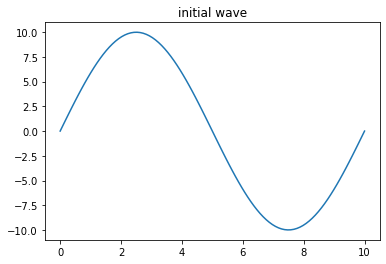

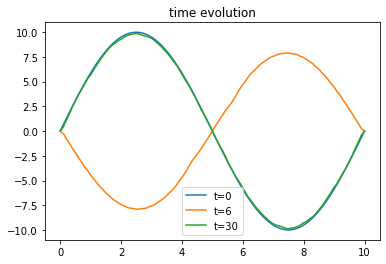

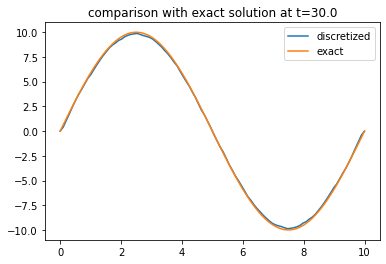

In [35]:
####Implementation of simple wave equation
###For resource check 
#http://hplgit.github.io/num-methods-for-PDEs/doc/pub/wave/sphinx/._main_wave001.html#sketch-of-an-implementation
Nx=100
c=1
Amplitude=10
L=10
x_range=np.linspace(0,L,Nx)
dx=np.mean(x_range[1:]-x_range[0:-1])
u_init=Amplitude*np.sin(2*np.pi*x_range/L)
plt.plot(x_range,u_init)
plt.title("initial wave")
plt.show()

Nt=2000
t_range=np.linspace(0,30,Nt)
dt=np.mean(t_range[1:]-t_range[0:-1])


#create lattice
u_lattice=np.zeros([Nt,Nx]) 
#insert initial state as the first time row
u_lattice[0]=u_init
# Calculate first time step
u_lattice[1][1:-1]=u_lattice[0][1:-1] + 1/2*c**2*(dt/dx)**2*( np.roll(u_lattice[0][1:-1],1) 
                                                             + np.roll(u_lattice[0][1:-1],-1)
                                                             -2*u_lattice[0][1:-1])
## Insert boundaries
u_lattice[1::,0]=u_init[0]
u_lattice[1::,-1]=u_init[-1]
for t in range(2,Nt):
    u_lattice[t][1:-1]=2*u_lattice[t-1][1:-1]-u_lattice[t-2][1:-1] + c**2*(dt/dx)**2*( np.roll(u_lattice[t-1][1:-1],1) 
                                                                                        + np.roll(u_lattice[t-1][1:-1],-1)
                                                                                        -2*u_lattice[t-1][1:-1])
    
plt.plot(x_range,u_lattice[0],label="t=%.f"%t_range[0])
plt.plot(x_range,u_lattice[Nt//5],label="t=%.f"%t_range[Nt//5])
plt.plot(x_range,u_lattice[-1],label="t=%.f"%t_range[-1])
plt.legend()
plt.title("time evolution")
plt.show()

def u_exact(x,t):
    return Amplitude*np.sin(2*np.pi*x/L)*np.cos(2*np.pi*c*t/L)
i=-1
plt.plot(x_range,u_lattice[i],label="discretized")
plt.plot(x_range,u_exact(x_range,t_range[i]),label="exact")
plt.title("comparison with exact solution at t=%.1f"%t_range[i])
plt.legend()
plt.show()

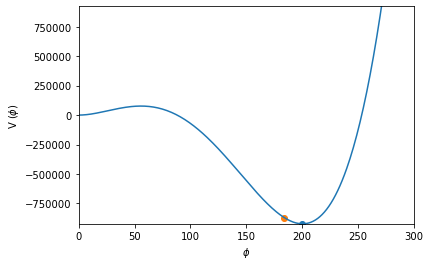

Difference between global minimum and the scape point is  15.90695302395892


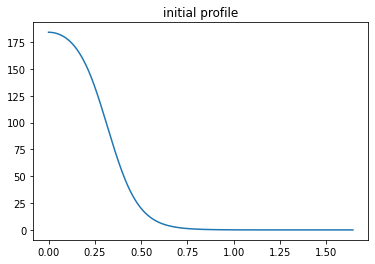

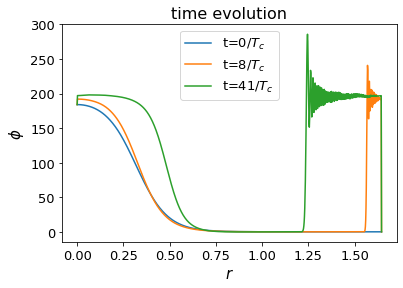

CPU times: user 2.07 s, sys: 83.2 ms, total: 2.15 s
Wall time: 2.15 s


In [11]:
%%time
#Definition of the potential
#Formulas drawn from the paper "Bubble growth and droplet decay in cosmological phase transitions"
Tc = 100.
L = 0.1*Tc**4
sigma = 0.1*Tc**3
lc = 6/Tc
T0 = Tc/(1+6*sigma/(L*lc))**0.5
alpha = 1/(2/3*sigma*lc**5*Tc**2)**0.5
gamma = (L+6*sigma/lc)/(6*sigma*lc*Tc**2)
lam = 1/(3*sigma*lc**3)
Tn = 90.
def V(phi): return 0.5*gamma*(Tn**2-T0**2)*phi**2- 1/3*alpha*Tn*phi**3 + 0.25*lam*phi**4
def dV(phi): return gamma*(Tn**2-T0**2)*phi-alpha*Tn*phi**2+lam*phi**3
xi = np.array(range(400))
Vmin = np.amin(V(xi))
phi_stable = xi[np.where(V(xi) == Vmin)[0]][0] ##find location of the global minimum
profile = SingleFieldInstanton(phi_stable, 0.0, V, dV).findProfile(npoints=1000)
plt.plot(xi, V(xi))
plt.xlabel(r"$\phi$")
plt.ylabel(r"V ($\phi$)")
plt.scatter(phi_stable,Vmin)
plt.scatter(profile.Phi[0],V(profile.Phi[0]))
plt.xlim(0,300)
plt.ylim(Vmin,-Vmin)
plt.show()
print("Difference between global minimum and the scape point is ",phi_stable-profile.Phi[0])


####Implementation of Higgs EOM equation
Nr=1000
R=profile.R[-1]
r_range=np.linspace(0,2*R,Nr)
dr=np.mean(r_range[1:]-r_range[:-1])

Nt=10000
t_range=np.linspace(0,0.5*R,Nt)
dt=np.mean(t_range[1:]-t_range[:-1])


#define the initial state
fphi = interpolate.interp1d(profile.R, profile.Phi, fill_value=(0), bounds_error=False)
phi_init=fphi(r_range/1.32)
plt.plot(r_range,phi_init)
plt.title("initial profile")
plt.show()



#create lattice
phi_lattice=np.zeros([Nt,Nr]) 
#insert initial state as the first time row
phi_lattice[0]=phi_init
# Calculate first time step
phi_lattice[1][1:-1]=phi_lattice[0][1:-1] 
phi_lattice[1][1:-1] += dt**2/2/dr**2*(np.roll(phi_lattice[0][1:-1],1) + np.roll(phi_lattice[0][1:-1],-1)-2*phi_lattice[0][1:-1])
phi_lattice[1][1:-1] += dt**2/2/dr/r_range[1:-1]*(-np.roll(phi_lattice[0][1:-1],1) + np.roll(phi_lattice[0][1:-1],-1))
phi_lattice[1][1:-1] +=-dt**2/2*dV(phi_lattice[0][1:-1])
## Insert boundaries
phi_lattice[1::,0]=profile.Phi[0]
phi_lattice[1::,-1]=phi_init[-1]

for t in range(2,Nt):
    phi_lattice[t][1:-1]=2*phi_lattice[t-1][1:-1]-phi_lattice[t-2][1:-1]
    phi_lattice[t][1:-1]+=dt**2/dr**2*(np.roll(phi_lattice[t-1][1:-1],1) + np.roll(phi_lattice[t-1][1:-1],-1)-2*phi_lattice[t-1][1:-1])
    phi_lattice[t][1:-1]+=dt**2/dr/r_range[1:-1]*(-np.roll(phi_lattice[t-1][1:-1],1) + np.roll(phi_lattice[t-1][1:-1],-1))
    phi_lattice[t][1:-1] +=-dt**2*dV(phi_lattice[t-1][1:-1])
    
    
    
plt.plot(r_range,phi_lattice[0],label="t=%.f"%(t_range[0]*Tc)+"$/T_c$")
plt.plot(r_range,phi_lattice[Nt//5],label="t=%.f"%(t_range[Nt//5]*Tc)+"$/T_c$")
plt.plot(r_range,phi_lattice[-1],label="t=%.f"%(t_range[-1]*Tc)+"$/T_c$")
plt.legend(fontsize=13)
plt.title("time evolution",fontsize=16)
#plt.xlim(r_range[1],r_range[-500])
plt.xlabel("$r$",size=15)
plt.ylabel("$\\phi$",size=15)
plt.xticks(size=13)
plt.yticks(size=13)
plt.show()


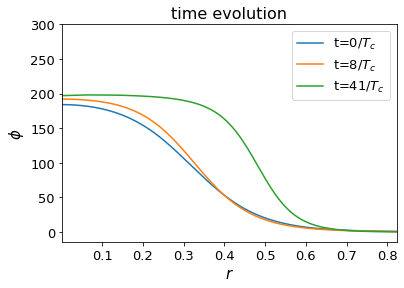

In [12]:
plt.plot(r_range,phi_lattice[0],label="t=%.f"%(t_range[0]*Tc)+"$/T_c$")
plt.plot(r_range,phi_lattice[Nt//5],label="t=%.f"%(t_range[Nt//5]*Tc)+"$/T_c$")
plt.plot(r_range,phi_lattice[-1],label="t=%.f"%(t_range[-1]*Tc)+"$/T_c$")
plt.legend(fontsize=13)
plt.title("time evolution",fontsize=16)
plt.xlim(r_range[1],r_range[-500])
plt.xlabel("$r$",size=15)
plt.ylabel("$\\phi$",size=15)
plt.xticks(size=13)
plt.yticks(size=13)
plt.show()
